<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/05_cidades_gemeas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/05_cidades_gemeas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resultado final, notebook 05: cidades gêmeas

**Objetivo:** para cada cidade em destaque do notebook 04, encontrar uma **cidade gêmea**: um município parecido em
tamanho e região, mas que recebe o valor **normal** do RN por habitante. Os pares servem para o notebook 06 comparar
se o dinheiro a mais faz diferença.

**Critérios de seleção (só estes dois):**

| Critério | Como entra |
|---|---|
| **Mesma mesorregião** | Obrigatório: a gêmea tem que ser da mesma mesorregião do IBGE (clima, economia e distância da capital parecidos) |
| **População parecida** | A mais próxima em proporção: 3.000 e 3.300 habitantes são tão parecidos quanto 30.000 e 33.000 |

**Baixa renda não é critério de seleção.** Ela entra como um **parâmetro de comparação**, junto com saúde, educação e
saneamento no notebook 06. A pergunta é: duas cidades do mesmo tamanho e da mesma região, uma recebe muito mais
dinheiro; a que recebe mais tem menos pobreza?

**Quem pode ser gêmea:** municípios que não são destaque e que recebem por habitante até o 3º quartil **do seu porte**
(os 75% que menos recebem entre os municípios do mesmo tamanho). Assim a gêmea é um município "comum", e não outra
cidade que também recebe muito.

_Por que comparar dentro do porte:_ municípios pequenos recebem naturalmente mais por habitante, porque uma parte do
ICMS é dividida em partes iguais entre os 167 municípios (notebook 06). Um teto único para o RN deixaria de fora quase
todos os municípios pequenos, e as destaques pequenas (Galinhos, Bodó) ficariam com gêmeas muito maiores.

**Arquivo gerado:** `resultado_final/saida/05_pares_gemeos.csv`, uma linha por par.

## 1. Bibliotecas e bases

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.optimize import linear_sum_assignment

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
ANOS = [2020, 2021, 2022, 2023]
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
ROXO, CINZA, CINZA_CLARO = '#7d55c7', '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, tentativas=3, **kwargs):
    """Lê do GitHub do projeto (tenta de novo se a conexão cair); se não conseguir, lê a cópia local (mesmo caminho)."""
    for _ in range(tentativas):
        try:
            return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
        except Exception as e:
            erro = e
            if '404' in str(e):
                break
            time.sleep(3)
    if os.path.exists(caminho):
        return pd.read_csv(caminho, **kwargs)
    if '404' in str(erro):
        raise FileNotFoundError(
            f'O arquivo "{caminho}" não está no GitHub do projeto. '
            f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
            'e rode a célula de novo.') from None
    raise ConnectionError(
        f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
        f'Erro original: {erro}') from None

os.makedirs('resultado_final/saida', exist_ok=True)

uni = ler_csv('resultado_final/saida/04_base_unificada_2020_2023.csv')
longo = ler_csv('resultado_final/saida/04_base_unificada_municipio_ano.csv')
destaques_04 = ler_csv('resultado_final/saida/04_cidades_destaque.csv')
censo = ler_csv('dados/ibge/censo2022_renda_rn.csv')[['cod_ibge', 'pct_ate_meio_sm_censo', 'renda_media_pc']]
uni = uni.merge(censo, on='cod_ibge', how='left')
assert len(uni) == 167 and uni['pct_ate_meio_sm_censo'].notna().all()

FONTES = [('Repasses obrigatórios', AZUL), ('Convênios', VERDE), ('Emendas sem convênio (Pix e outras)', LARANJA),
          ('Emendas em convênios anteriores a 2020', AMARELO)]

## 2. As cidades em destaque

As 6 cidades do notebook 04 e a **Serra do Mel**, incluída como **caso de fronteira**: ela é a 7ª que mais recebe por
habitante e era destaque quando se olhavam só os repasses, mas ficou logo abaixo do limite ao somar convênios e
emendas.

In [2]:
FRONTEIRA = ['Serra do Mel']
DESTAQUES = destaques_04['municipio'].tolist() + FRONTEIRA
uni['grupo'] = np.where(uni['municipio'].isin(destaques_04['municipio']), 'Destaque',
                        np.where(uni['municipio'].isin(FRONTEIRA), 'Destaque (fronteira)', 'Demais'))
(uni[uni['municipio'].isin(DESTAQUES)].set_index('municipio')
 [['grupo', 'mesorregiao', 'populacao', 'total_pc_ano', 'vezes_mediana', 'posicao_total']]
 .sort_values('posicao_total')
 .rename(columns={'grupo': 'Grupo', 'mesorregiao': 'Mesorregião', 'populacao': 'População',
                  'total_pc_ano': 'Total (R$/hab/ano)', 'vezes_mediana': 'Vezes a mediana', 'posicao_total': 'Posição'}))

,Grupo,Mesorregião,População,Total (R$/hab/ano),Vezes a mediana,Posição
municipio,,,,,,
Guamaré,Destaque,Central Potiguar,15295,"13,330.3",18.0,1
Galinhos,Destaque,Central Potiguar,2104,"5,603.6",7.6,2
Parazinho,Destaque,Agreste Potiguar,4801,"5,258.0",7.1,3
São Bento do Norte,Destaque,Central Potiguar,3304,"4,952.7",6.7,4
Pedra Grande,Destaque,Leste Potiguar,3618,"4,938.5",6.7,5
Bodó,Destaque,Central Potiguar,2306,"4,211.0",5.7,6
Serra do Mel,Destaque (fronteira),Oeste Potiguar,13091,"2,247.3",3.0,7


## 3. Escolha das gêmeas

**Distância de população:** `|log(pop. da destaque) − log(pop. da candidata)|`. Em palavras: o quanto uma população é
maior que a outra, em proporção. Uma distância de 0,10 quer dizer populações cerca de 10% diferentes.

**Sem repetir gêmea:** quatro destaques são da mesma mesorregião (Central Potiguar). Se cada uma escolhesse sozinha a
candidata mais próxima, duas poderiam escolher a mesma cidade. Por isso escolhemos todos os pares **de uma vez**, de
modo que a soma das distâncias seja a menor possível e cada candidata seja usada no máximo uma vez (o "problema de
atribuição", resolvido com `scipy.optimize.linear_sum_assignment`).

In [3]:
TETO_PORTE = uni[uni['grupo'] == 'Demais'].groupby('porte')['total_pc_ano'].quantile(0.75)
uni['teto_gemea'] = uni['porte'].map(TETO_PORTE)
candidatas = uni[(uni['grupo'] == 'Demais') & (uni['total_pc_ano'] <= uni['teto_gemea'])].reset_index(drop=True)
alvo = uni[uni['municipio'].isin(DESTAQUES)].set_index('municipio').loc[DESTAQUES].reset_index()
print(f'Candidatas a gêmea: {len(candidatas)} municípios')
print('Teto por porte (R$ por habitante por ano):', ' | '.join(f'{p}: {virgula(v, 0)}' for p, v in TETO_PORTE.items()))

distancia = np.abs(np.log(alvo['populacao'].values[:, None]) - np.log(candidatas['populacao'].values[None, :]))
outra_meso = alvo['mesorregiao'].values[:, None] != candidatas['mesorregiao'].values[None, :]
custo = np.where(outra_meso, 1e6, distancia)            # outra mesorregião: proibido
linhas_idx, colunas_idx = linear_sum_assignment(custo)
assert (custo[linhas_idx, colunas_idx] < 1e6).all(), 'alguma destaque ficou sem gêmea na mesma mesorregião'

pares = pd.DataFrame({'destaque': alvo.loc[linhas_idx, 'municipio'].values,
                      'gemea': candidatas.loc[colunas_idx, 'municipio'].values,
                      'distancia_pop': custo[linhas_idx, colunas_idx]})

# As 3 candidatas mais próximas de cada destaque, para o grupo conferir (e trocar, se quiser)
opcoes = []
for i, linha in alvo.iterrows():
    ordem = np.argsort(custo[i])[:3]
    for pos, j in enumerate(ordem, start=1):
        c = candidatas.loc[j]
        opcoes.append({'Destaque': linha['municipio'], 'Opção': pos, 'Candidata': c['municipio'],
                       'População': c['populacao'],
                       'Diferença de população': f'{virgula((c["populacao"] / linha["populacao"] - 1) * 100, 0)}%',
                       'Total (R$/hab/ano)': c['total_pc_ano'],
                       'Escolhida': '✔' if c['municipio'] in pares['gemea'].values and
                                           pares.set_index('destaque').loc[linha['municipio'], 'gemea'] == c['municipio'] else ''})
pd.DataFrame(opcoes).set_index(['Destaque', 'Opção'])

Candidatas a gêmea: 119 municípios
Teto por porte (R$ por habitante por ano): 10–20 mil: 767 | 20–50 mil: 701 | 5–10 mil: 777 | até 5 mil: 1.209 | mais de 50 mil: 742


Candidata  População  \
Destaque           Opção                                        
Guamaré            1            Jardim de Piranhas      13977   
                   2              Jardim do Seridó      11655   
                   3                       Angicos      11632   
Galinhos           1              Fernando Pedroza       2938   
                   2       Caiçara do Rio do Vento       3268   
                   3                  São Fernando       3492   
Parazinho          1               Bento Fernandes       4807   
                   2                Lajes Pintadas       4787   
                   3                   Santa Maria       4847   
São Bento do Norte 1       Caiçara do Rio do Vento       3268   
                   2                  São Fernando       3492   
                   3              Fernando Pedroza       2938   
Pedra Grande       1      Senador Georgino Avelino       4065   
                   2                     Vila Flor       3174   
                   3                        Pureza       9362   
Bodó               1              Fernando Pedroza       2938   
                   2       Caiçara do Rio do Vento       3268   
                   3                  São Fernando       3492   
Serra do Mel       1                    Alexandria      13640   
                   2                     Ipanguaçu      14131   
                   3                          Patu      11007   

                         Diferença de população  Total (R$/hab/ano) Escolhida  
Destaque           Opção                                                       
Guamaré            1                        -9%               657.3         ✔  
                   2                       -24%               564.8            
                   3                       -24%               557.3            
Galinhos           1                        40%             1,126.8         ✔  
                   2                        55%               977.2            
                   3                        66%             1,170.9            
Parazinho          1                         0%               773.6         ✔  
                   2                        -0%               643.6            
                   3                         1%               736.2            
São Bento do Norte 1                        -1%               977.2            
                   2                         6%             1,170.9         ✔  
                   3                       -11%             1,126.8            
Pedra Grande       1                        12%               762.8         ✔  
                   2                       -12%               877.6            
                   3                       159%               463.4            
Bodó               1                        27%             1,126.8            
                   2                        42%               977.2         ✔  
                   3                        51%             1,170.9            
Serra do Mel       1                         4%               513.8         ✔  
                   2                         8%               581.6            
                   3                       -16%               594.8

## 4. Os pares

In [4]:
info = uni.set_index('municipio')
COLS = ['cod_ibge', 'mesorregiao', 'populacao', 'total_pc_ano', 'rep_pc_ano', 'conv_pc_ano', 'emendas_sem_conv_pc_ano',
        'emendas_conv_anterior_pc_ano', 'rep_pct', 'posicao_total', 'pct_baixa_renda', 'pct_ate_meio_sm_censo',
        'renda_media_pc', 'pib_per_capita']
for papel, coluna in [('d', 'destaque'), ('g', 'gemea')]:
    dados = info.loc[pares[coluna], COLS].reset_index(drop=True).add_prefix(f'{papel}_')
    pares = pd.concat([pares, dados], axis=1)
pares['fronteira'] = pares['destaque'].isin(FRONTEIRA)
pares['dif_populacao_pct'] = (pares['g_populacao'] / pares['d_populacao'] - 1) * 100
pares['vezes_mais_dinheiro'] = pares['d_total_pc_ano'] / pares['g_total_pc_ano']
pares['dif_baixa_renda_pp'] = pares['d_pct_baixa_renda'] - pares['g_pct_baixa_renda']
pares['dif_pobreza_censo_pp'] = pares['d_pct_ate_meio_sm_censo'] - pares['g_pct_ate_meio_sm_censo']
pares = pares.sort_values('d_total_pc_ano', ascending=False).reset_index(drop=True)

(pares.set_index('destaque')[['gemea', 'd_mesorregiao', 'd_populacao', 'g_populacao', 'dif_populacao_pct',
                              'd_total_pc_ano', 'g_total_pc_ano', 'vezes_mais_dinheiro']]
 .rename(columns={'gemea': 'Gêmea', 'd_mesorregiao': 'Mesorregião', 'd_populacao': 'Pop. destaque',
                  'g_populacao': 'Pop. gêmea', 'dif_populacao_pct': 'Diferença de pop. (%)',
                  'd_total_pc_ano': 'Destaque (R$/hab/ano)', 'g_total_pc_ano': 'Gêmea (R$/hab/ano)',
                  'vezes_mais_dinheiro': 'Vezes mais dinheiro'}))

,Gêmea,Mesorregião,Pop. destaque,Pop. gêmea,Diferença de pop. (%),Destaque (R$/hab/ano),Gêmea (R$/hab/ano),Vezes mais dinheiro
destaque,,,,,,,,
Guamaré,Jardim de Piranhas,Central Potiguar,15295,13977,-8.6,"13,330.3",657.3,20.3
Galinhos,Fernando Pedroza,Central Potiguar,2104,2938,39.6,"5,603.6","1,126.8",5.0
Parazinho,Bento Fernandes,Agreste Potiguar,4801,4807,0.1,"5,258.0",773.6,6.8
São Bento do Norte,São Fernando,Central Potiguar,3304,3492,5.7,"4,952.7","1,170.9",4.2
Pedra Grande,Senador Georgino Avelino,Leste Potiguar,3618,4065,12.4,"4,938.5",762.8,6.5
Bodó,Caiçara do Rio do Vento,Central Potiguar,2306,3268,41.7,"4,211.0",977.2,4.3
Serra do Mel,Alexandria,Oeste Potiguar,13091,13640,4.2,"2,247.3",513.8,4.4


### 4.1 Mesmo tamanho, dinheiro muito diferente

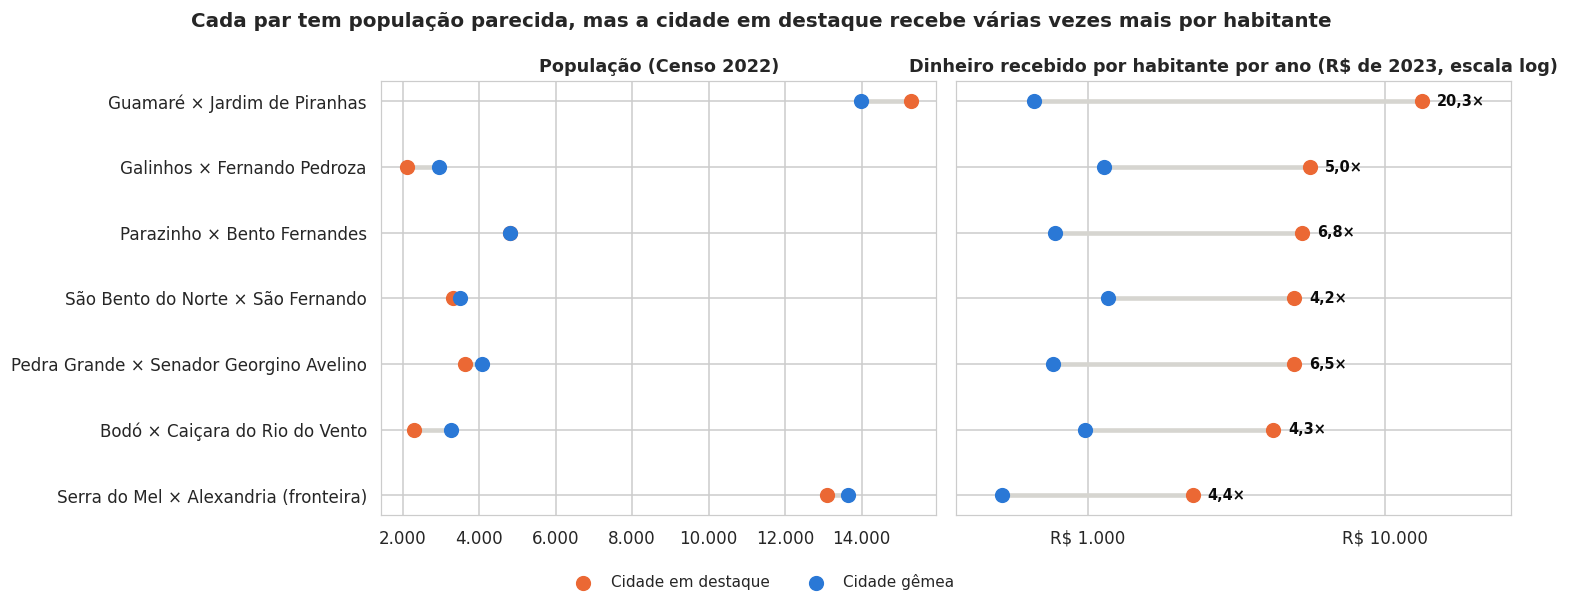

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
y = np.arange(len(pares))[::-1]
for ax, (col, titulo, log) in zip(axes, [('populacao', 'População (Censo 2022)', False),
                                         ('total_pc_ano', 'Dinheiro recebido por habitante por ano (R$ de 2023, escala log)', True)]):
    for yi, (_, p) in zip(y, pares.iterrows()):
        ax.plot([p[f'g_{col}'], p[f'd_{col}']], [yi, yi], color=CINZA_CLARO, linewidth=3, zorder=1)
    ax.scatter(pares[f'd_{col}'], y, s=80, color=LARANJA, zorder=3, label='Cidade em destaque')
    ax.scatter(pares[f'g_{col}'], y, s=80, color=AZUL, zorder=3, label='Cidade gêmea')
    if log:
        ax.set_xscale('log')
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'R$ {v:,.0f}'.replace(',', '.')))
        for yi, (_, p) in zip(y, pares.iterrows()):
            ax.text(p['d_total_pc_ano'] * 1.12, yi, f'{virgula(p["vezes_mais_dinheiro"])}×', va='center', fontsize=9.5,
                    fontweight='bold', color=TEXTO)
        ax.set_xlim(pares['g_total_pc_ano'].min() * 0.7, pares['d_total_pc_ano'].max() * 2)
    else:
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
    ax.set_title(titulo, fontsize=11.5)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f'{p.destaque} × {p.gemea}' + (' (fronteira)' if p.fronteira else '') for p in pares.itertuples()])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0))
fig.suptitle('Cada par tem população parecida, mas a cidade em destaque recebe várias vezes mais por habitante',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

### 4.2 Ano a ano em cada par

Dinheiro recebido por habitante em cada ano, por fonte. Cada linha é um par: destaque à esquerda, gêmea à direita.
As duas colunas usam a mesma escala dentro do par, para a diferença ficar visível.

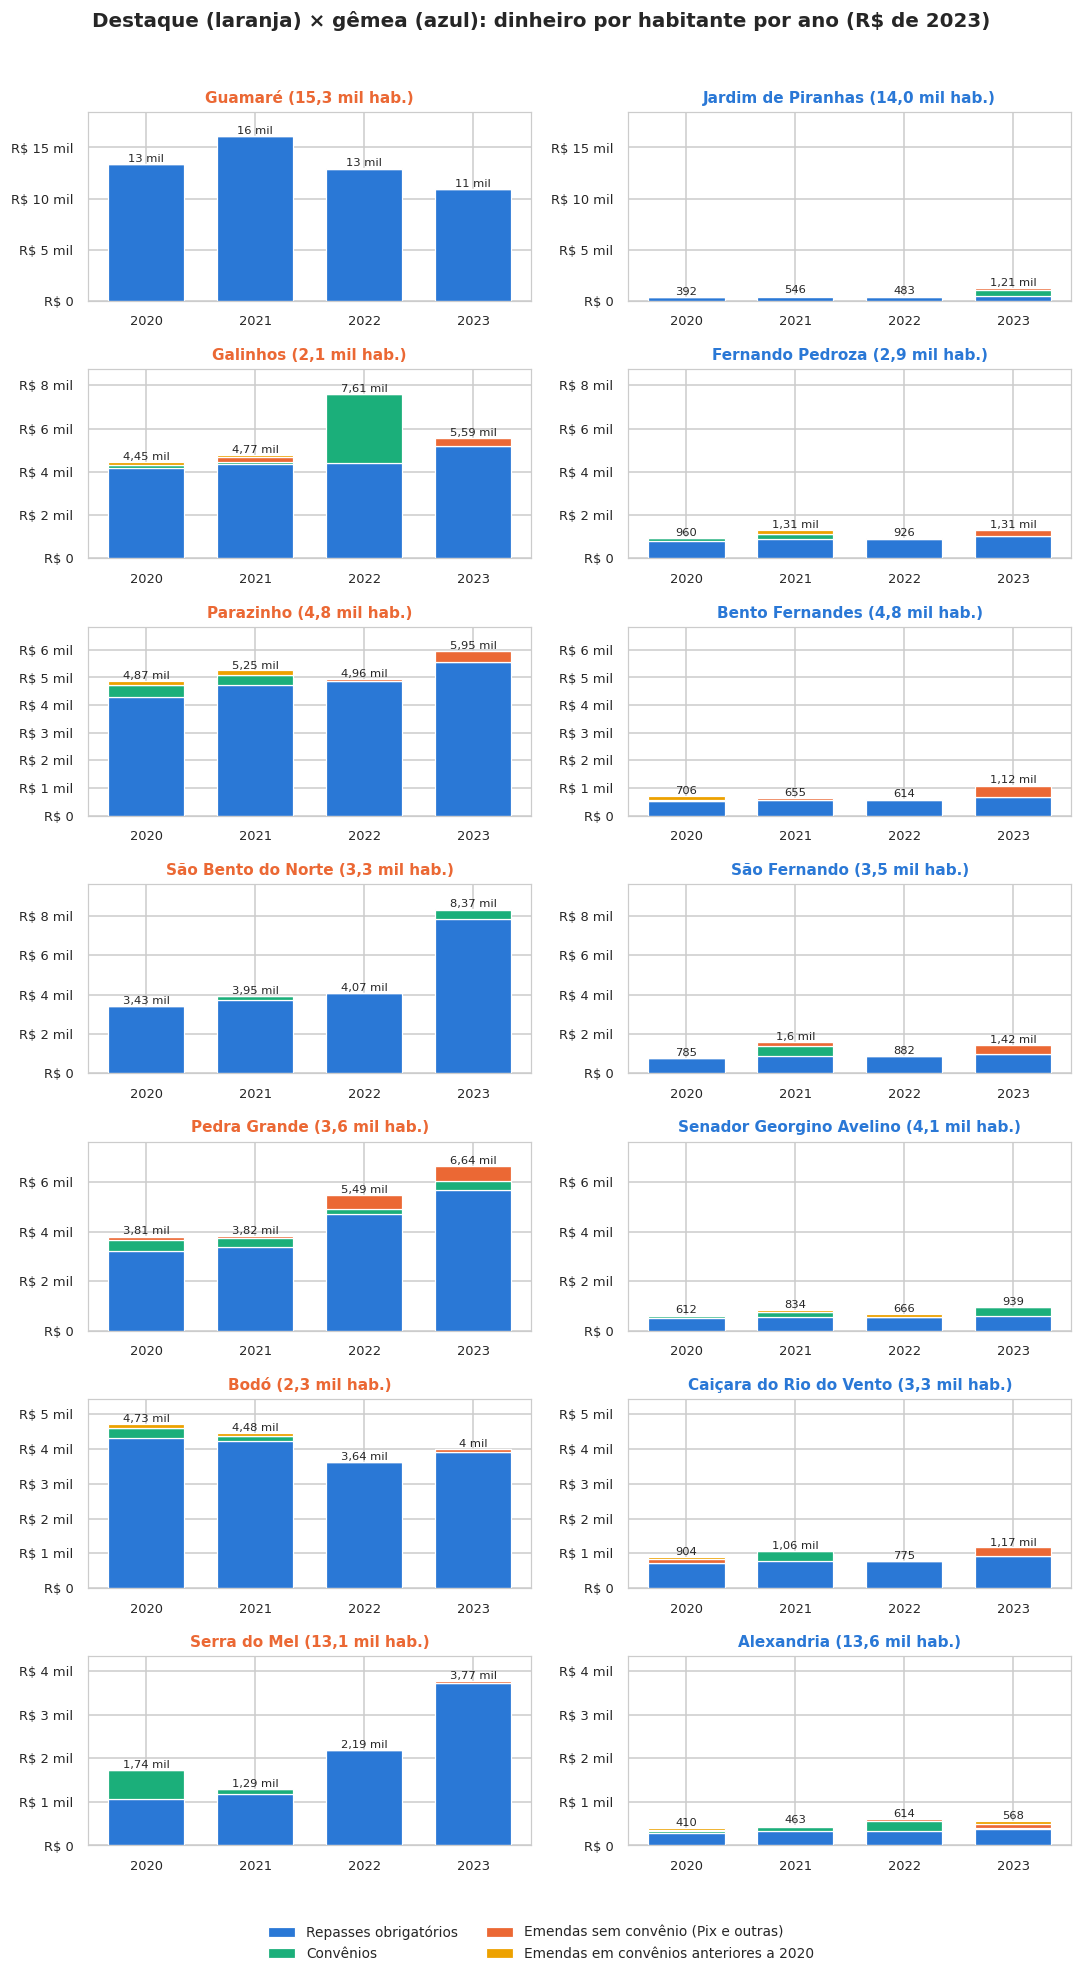

In [6]:
def grafico_par(destaque, gemea, ax_d, ax_g):
    maximo = 0
    for ax, nome in [(ax_d, destaque), (ax_g, gemea)]:
        dados = (longo[longo['municipio'] == nome].pivot_table(index='ano', columns='fonte', values='valor_pc', aggfunc='sum')
                 .reindex(index=ANOS, columns=[f for f, _ in FONTES]).fillna(0))
        fundo = np.zeros(len(ANOS))
        for fonte, cor in FONTES:
            ax.bar(ANOS, dados[fonte], bottom=fundo, color=cor, width=0.7, edgecolor='white', linewidth=0.8, label=fonte)
            fundo += dados[fonte].values
        for x, total in zip(ANOS, fundo):
            ax.text(x, total, reais(total).replace('R$ ', ''), ha='center', va='bottom', fontsize=7.5)
        maximo = max(maximo, fundo.max())
        linha = info.loc[nome]
        ax.set_title(f'{nome} ({virgula(linha["populacao"] / 1000)} mil hab.)', fontsize=10,
                     color=LARANJA if nome == destaque else AZUL)
        ax.set_xticks(ANOS)
        ax.tick_params(labelsize=8.5)
        ax.yaxis.set_major_formatter(FORMATO_REAIS)
    for ax in (ax_d, ax_g):
        ax.set_ylim(0, maximo * 1.15)

fig, axes = plt.subplots(len(pares), 2, figsize=(10, 2.6 * len(pares)))
for (ax_d, ax_g), p in zip(axes, pares.itertuples()):
    grafico_par(p.destaque, p.gemea, ax_d, ax_g)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0))
fig.suptitle('Destaque (laranja) × gêmea (azul): dinheiro por habitante por ano (R$ de 2023)', fontsize=13,
             fontweight='bold')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

## 5. Uma primeira olhada na baixa renda (parâmetro de comparação)

Não foi usada para escolher os pares. Aqui só mostramos como as duas cidades de cada par estão, como prévia do notebook
06. Duas medidas:

- **CadÚnico:** pessoas de baixa renda (até ½ salário mínimo por pessoa) em % da população, média de 2020 a 2023;
- **Censo 2022:** % da população com renda de até ½ salário mínimo por pessoa. É a medida mais confiável, porque o
  CadÚnico depende de a família se cadastrar e pode passar de 100% da população em alguns municípios.

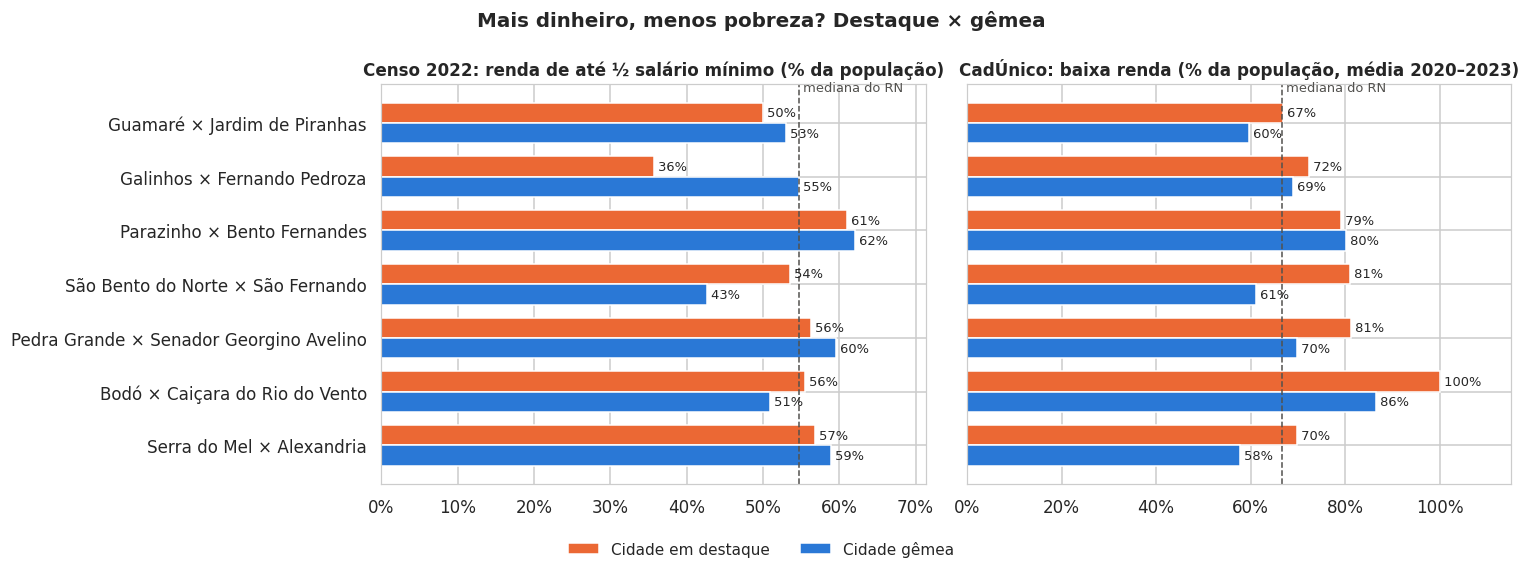

,Gêmea,Vezes mais dinheiro,Censo: destaque (%),Censo: gêmea (%),Censo: diferença (p.p.),CadÚnico: destaque (%),CadÚnico: gêmea (%),CadÚnico: diferença (p.p.)
destaque,,,,,,,,
Guamaré,Jardim de Piranhas,20.3,49.9,53.1,-3.1,66.9,59.6,7.3
Galinhos,Fernando Pedroza,5.0,35.7,54.7,-18.9,72.3,69.1,3.2
Parazinho,Bento Fernandes,6.8,61.0,62.0,-1.0,79.2,80.3,-1.1
São Bento do Norte,São Fernando,4.2,53.6,42.6,10.9,81.0,61.2,19.8
Pedra Grande,Senador Georgino Avelino,6.5,56.3,59.5,-3.3,81.4,69.9,11.4
Bodó,Caiçara do Rio do Vento,4.3,55.5,50.9,4.7,100.2,86.5,13.7
Serra do Mel,Alexandria,4.4,56.8,58.9,-2.1,69.9,57.8,12.1


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
y = np.arange(len(pares))[::-1]
altura = 0.38
for ax, (col, titulo) in zip(axes, [('pct_ate_meio_sm_censo', 'Censo 2022: renda de até ½ salário mínimo (% da população)'),
                                    ('pct_baixa_renda', 'CadÚnico: baixa renda (% da população, média 2020–2023)')]):
    ax.barh(y + altura / 2, pares[f'd_{col}'], height=altura, color=LARANJA, label='Cidade em destaque')
    ax.barh(y - altura / 2, pares[f'g_{col}'], height=altura, color=AZUL, label='Cidade gêmea')
    for yi, (d, g) in zip(y, zip(pares[f'd_{col}'], pares[f'g_{col}'])):
        ax.text(d, yi + altura / 2, f' {virgula(d, 0)}%', va='center', fontsize=8.5)
        ax.text(g, yi - altura / 2, f' {virgula(g, 0)}%', va='center', fontsize=8.5)
    ax.axvline(uni[col].median(), color=TEXTO_2, linestyle='--', linewidth=1)
    ax.text(uni[col].median(), y.max() + 0.6, ' mediana do RN', fontsize=8.5, color=TEXTO_2)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    ax.set_xlim(0, max(pares[f'd_{col}'].max(), pares[f'g_{col}'].max()) * 1.15)
    ax.set_title(titulo, fontsize=11)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f'{p.destaque} × {p.gemea}' for p in pares.itertuples()])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0))
fig.suptitle('Mais dinheiro, menos pobreza? Destaque × gêmea', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

(pares.set_index('destaque')[['gemea', 'vezes_mais_dinheiro', 'd_pct_ate_meio_sm_censo', 'g_pct_ate_meio_sm_censo',
                              'dif_pobreza_censo_pp', 'd_pct_baixa_renda', 'g_pct_baixa_renda', 'dif_baixa_renda_pp']]
 .rename(columns={'gemea': 'Gêmea', 'vezes_mais_dinheiro': 'Vezes mais dinheiro',
                  'd_pct_ate_meio_sm_censo': 'Censo: destaque (%)', 'g_pct_ate_meio_sm_censo': 'Censo: gêmea (%)',
                  'dif_pobreza_censo_pp': 'Censo: diferença (p.p.)', 'd_pct_baixa_renda': 'CadÚnico: destaque (%)',
                  'g_pct_baixa_renda': 'CadÚnico: gêmea (%)', 'dif_baixa_renda_pp': 'CadÚnico: diferença (p.p.)'}))

_p.p. = pontos percentuais: a diferença entre duas porcentagens (60% − 55% = 5 p.p.). Negativo: a destaque tem
menos pobreza que a gêmea._

## 6. Arquivo final

In [8]:
saida = pares[['destaque', 'd_cod_ibge', 'gemea', 'g_cod_ibge', 'fronteira', 'd_mesorregiao', 'd_populacao', 'g_populacao',
               'dif_populacao_pct', 'distancia_pop', 'd_total_pc_ano', 'g_total_pc_ano', 'vezes_mais_dinheiro',
               'd_rep_pct', 'g_rep_pct', 'd_pct_ate_meio_sm_censo', 'g_pct_ate_meio_sm_censo', 'd_pct_baixa_renda',
               'g_pct_baixa_renda']].rename(columns={'d_cod_ibge': 'cod_ibge_destaque', 'g_cod_ibge': 'cod_ibge_gemea',
                                                     'd_mesorregiao': 'mesorregiao'})
saida.to_csv('resultado_final/saida/05_pares_gemeos.csv', index=False)
assert saida['gemea'].is_unique and len(saida) == len(DESTAQUES)
print(f'05_pares_gemeos.csv: {len(saida)} pares')
saida[['destaque', 'gemea', 'fronteira', 'dif_populacao_pct', 'vezes_mais_dinheiro']]

05_pares_gemeos.csv: 7 pares


,destaque,gemea,fronteira,dif_populacao_pct,vezes_mais_dinheiro
0,Guamaré,Jardim de Piranhas,False,-8.6,20.3
1,Galinhos,Fernando Pedroza,False,39.6,5.0
2,Parazinho,Bento Fernandes,False,0.1,6.8
3,São Bento do Norte,São Fernando,False,5.7,4.2
4,Pedra Grande,Senador Georgino Avelino,False,12.4,6.5
5,Bodó,Caiçara do Rio do Vento,False,41.7,4.3
6,Serra do Mel,Alexandria,True,4.2,4.4


**Dicionário do `05_pares_gemeos.csv`** (prefixo `d_` = destaque, `g_` = gêmea; valores de 2020–2023 em R\$ de 2023):

| Coluna | O que é |
|---|---|
| `destaque`, `gemea`, `cod_ibge_*` | Nome e código IBGE das duas cidades do par |
| `fronteira` | `True` para a Serra do Mel, incluída como caso de fronteira |
| `mesorregiao` | Mesorregião das duas (é a mesma, por critério) |
| `d_populacao`, `g_populacao`, `dif_populacao_pct` | População (Censo 2022) e diferença da gêmea em relação à destaque |
| `distancia_pop` | Distância usada na escolha: `|log(pop. destaque) − log(pop. gêmea)|` |
| `*_total_pc_ano`, `vezes_mais_dinheiro` | Total recebido por habitante por ano (notebook 04) e a razão destaque ÷ gêmea |
| `*_rep_pct` | Parte do total que vem de repasses obrigatórios (%) |
| `*_pct_ate_meio_sm_censo`, `*_pct_baixa_renda` | Baixa renda pelo Censo 2022 e pelo CadÚnico (parâmetros de comparação, não critérios) |

## 7. Conclusões e próximos passos

**Os pares (2020–2023, em R\$ de 2023 por habitante por ano):**

| Destaque | Gêmea | Mesorregião | Diferença de população | Vezes mais dinheiro |
|---|---|---|---|---|
| Guamaré | Jardim de Piranhas | Central Potiguar | −9% | 20,3× |
| Galinhos | Fernando Pedroza | Central Potiguar | +40% | 5,0× |
| Parazinho | Bento Fernandes | Agreste Potiguar | 0% | 6,8× |
| São Bento do Norte | São Fernando | Central Potiguar | +6% | 4,2× |
| Pedra Grande | Senador Georgino Avelino | Leste Potiguar | +12% | 6,5× |
| Bodó | Caiçara do Rio do Vento | Central Potiguar | +42% | 4,3× |
| Serra do Mel (fronteira) | Alexandria | Oeste Potiguar | +4% | 4,4× |

1. **Em todos os pares a destaque recebe de 4 a 20 vezes mais por habitante**, com população parecida e na mesma
   mesorregião. É a base para o notebook 06 testar se esse dinheiro a mais aparece nos resultados.
2. **Cinco pares têm população quase igual** (até 12% de diferença). Galinhos e Bodó ficaram com gêmeas cerca de 40%
   maiores, porque os outros municípios muito pequenos da Central Potiguar também recebem acima do normal para o seu
   porte (Ipueira, Timbaúba dos Batistas, Jardim de Angicos). Ainda assim, todos estão no mesmo porte ("até 5 mil").
3. **Primeira olhada na baixa renda (Censo 2022):** mesmo recebendo várias vezes mais, a destaque tem pobreza
   parecida com a da gêmea na maioria dos pares. A diferença fica em até 3 pontos percentuais em quatro deles. Galinhos
   é a exceção (36% contra 55%), e em São Bento do Norte e Bodó a destaque tem **mais** pobreza que a gêmea.
4. **CadÚnico × Censo:** no CadÚnico, a destaque tem mais pessoas de baixa renda que a gêmea em 6 dos 7 pares. Isso
   pode refletir cadastro mais ativo (Bodó passa de 100% da população), e não mais pobreza. Por isso o Censo é a medida
   principal e o CadÚnico, complementar.

**Cuidados:**

- A gêmea é parecida em tamanho e região, **não em tudo**. Diferenças de economia, gestão e história também pesam; o
  par ajuda a comparar, mas não prova causa.
- As opções 2 e 3 de cada destaque estão na seção 3, caso o grupo queira trocar alguma gêmea.

**Próximo passo (notebook 06):** comparar destaques e gêmeas em dependência das transferências, em como o dinheiro é
gasto (SICONFI) e nos parâmetros sociais: baixa renda, saúde, educação e saneamento.